In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style

sns.set_style("whitegrid")

# Load original dataset

df = pd.read_csv("C:\\Users\\pro\\Student-Performance-Prediction\\dataset\\StudentPerformanceFactors.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
# Check exam score statistics

print("Minimum Score:", df["Exam_Score"].min())
print("Maximum Score:", df["Exam_Score"].max())
print("Mean Score:", df["Exam_Score"].mean())
print("Median Score:", df["Exam_Score"].median())

# Find scores above 100

unusual_scores = df[df["Exam_Score"] > 100]

print("\nRecords with scores above 100:")
display(unusual_scores)

Minimum Score: 55
Maximum Score: 101
Mean Score: 67.23565914938702
Median Score: 67.0

Records with scores above 100:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


In [3]:
# Display the highest 15 score frequencies

print(
    df["Exam_Score"]
    .value_counts()
    .sort_index()
    .tail(15)
)

Exam_Score
86     4
87     2
88     3
89     3
91     1
92     2
93     2
94     4
95     2
96     1
97     3
98     3
99     2
100    1
101    1
Name: count, dtype: int64


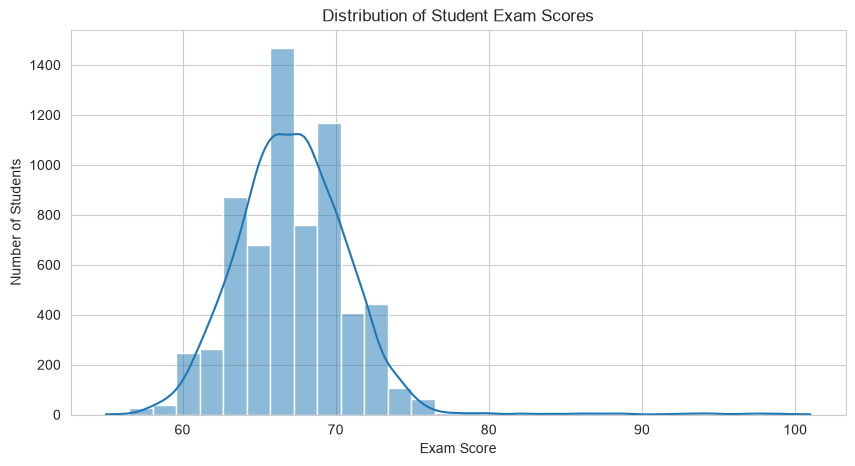

In [4]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Exam_Score",
    bins=30,
    kde=True
)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()

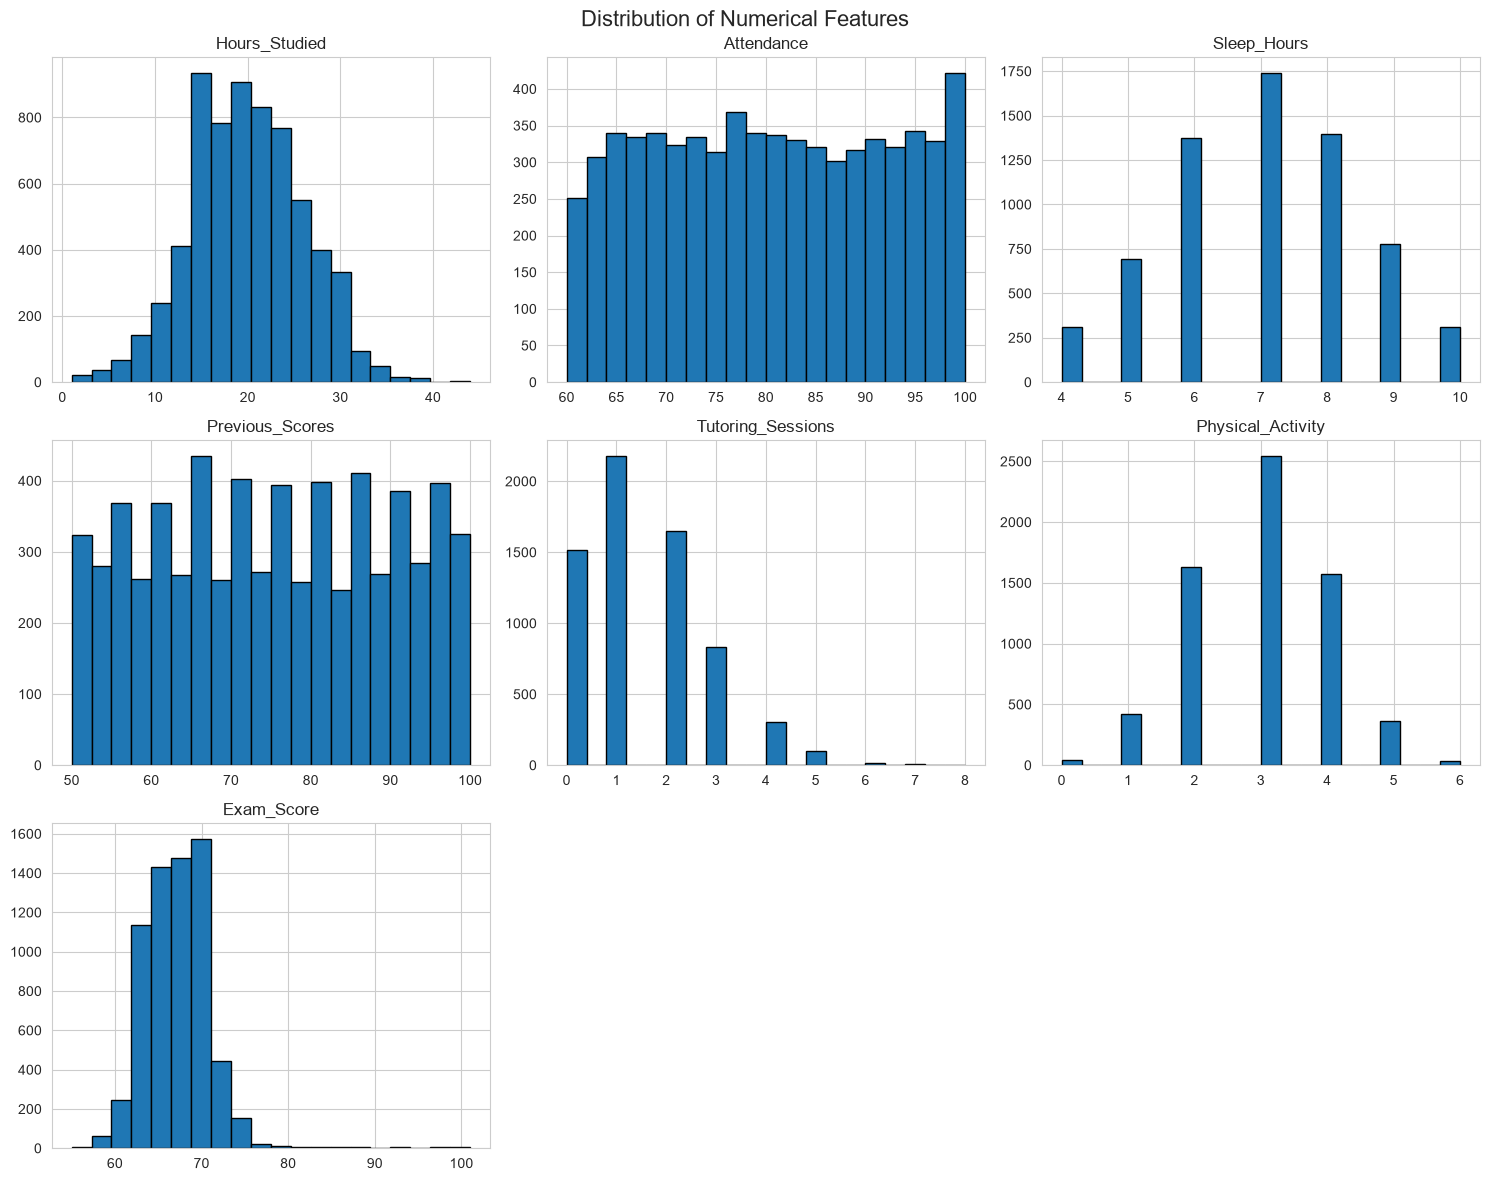

In [5]:
numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

df[numerical_columns].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)

plt.tight_layout()
plt.show()

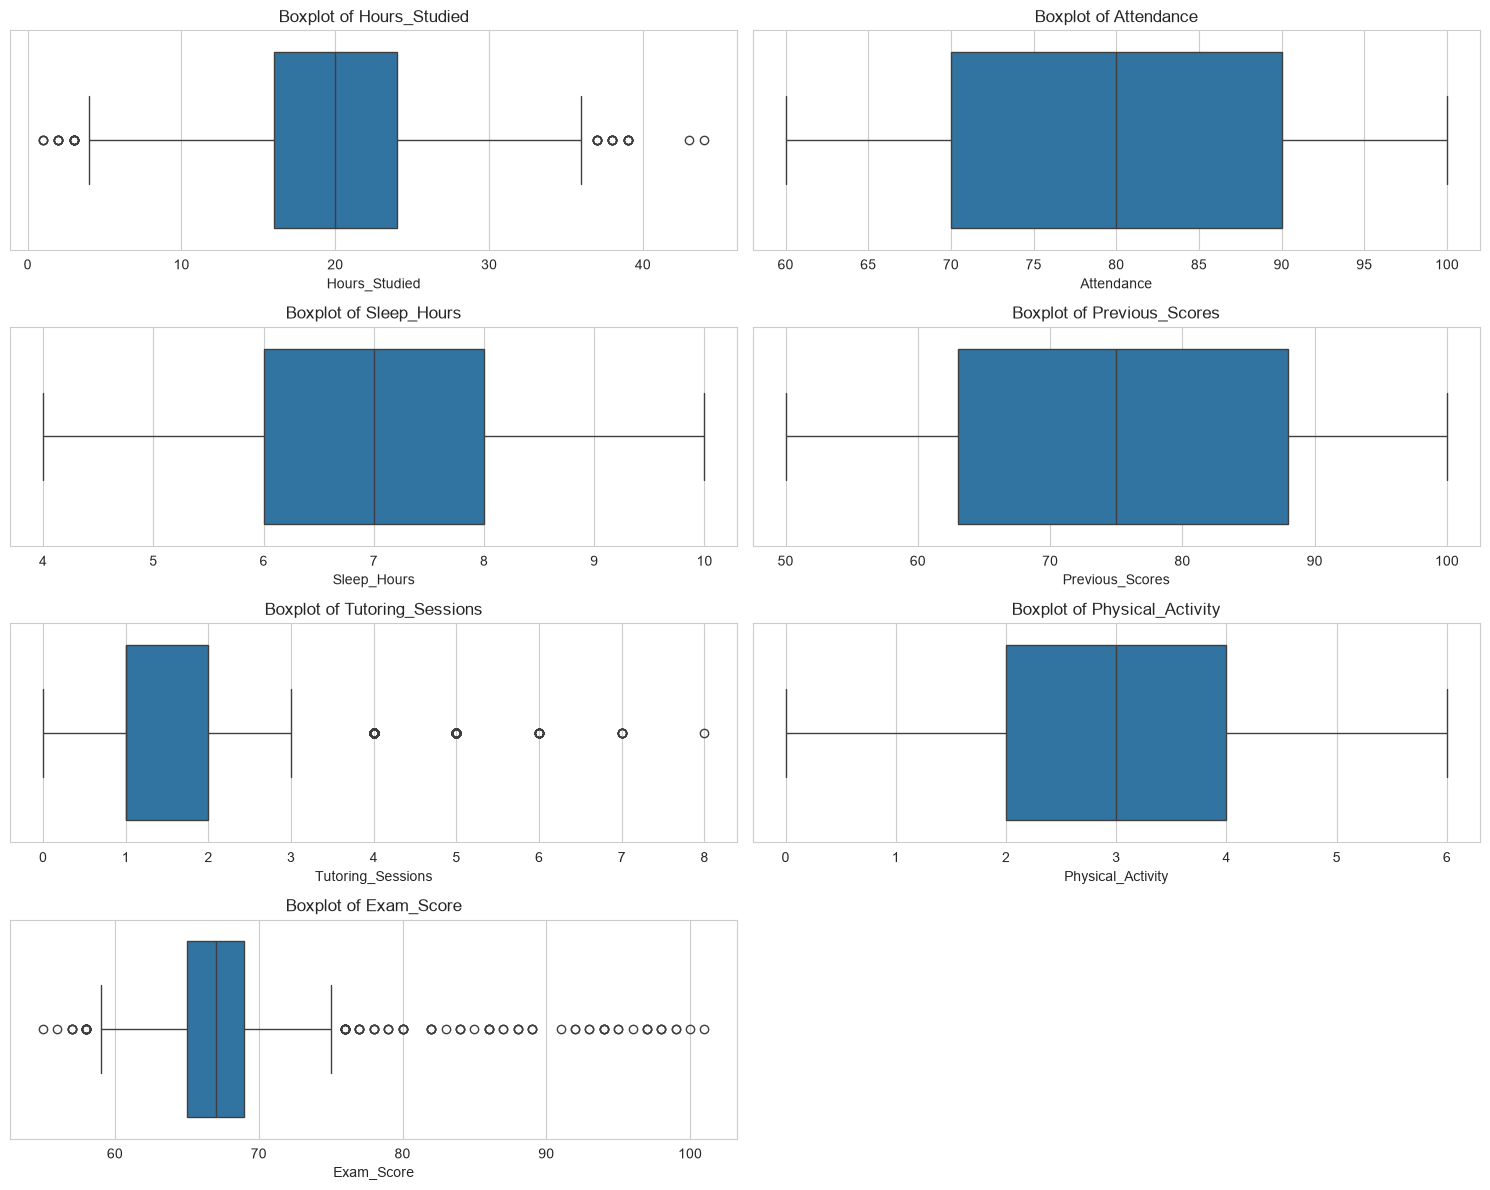

In [6]:
# Boxplot analysis of numerical features

numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

plt.figure(figsize=(15, 12))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(4, 2, i)

    sns.boxplot(x=df[column])

    plt.title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

In [7]:
# Detect potential outliers using IQR

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print("\nFeature:", column)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Potential Outliers:", len(outliers))


Feature: Hours_Studied
Lower Bound: 4.0
Upper Bound: 36.0
Potential Outliers: 43

Feature: Attendance
Lower Bound: 40.0
Upper Bound: 120.0
Potential Outliers: 0

Feature: Sleep_Hours
Lower Bound: 3.0
Upper Bound: 11.0
Potential Outliers: 0

Feature: Previous_Scores
Lower Bound: 25.5
Upper Bound: 125.5
Potential Outliers: 0

Feature: Tutoring_Sessions
Lower Bound: -0.5
Upper Bound: 3.5
Potential Outliers: 430

Feature: Physical_Activity
Lower Bound: -1.0
Upper Bound: 7.0
Potential Outliers: 0

Feature: Exam_Score
Lower Bound: 59.0
Upper Bound: 75.0
Potential Outliers: 104


In [8]:
# Display the unusual target record clearly

unusual_record = df.loc[df["Exam_Score"] > 100]

print(unusual_record.T.to_string())

                                   1525
Hours_Studied                        27
Attendance                           98
Parental_Involvement                Low
Access_to_Resources              Medium
Extracurricular_Activities          Yes
Sleep_Hours                           6
Previous_Scores                      93
Motivation_Level                    Low
Internet_Access                      No
Tutoring_Sessions                     5
Family_Income                      High
Teacher_Quality                    High
School_Type                      Public
Peer_Influence                 Positive
Physical_Activity                     3
Learning_Disabilities                No
Parental_Education_Level    High School
Distance_from_Home             Moderate
Gender                           Female
Exam_Score                          101


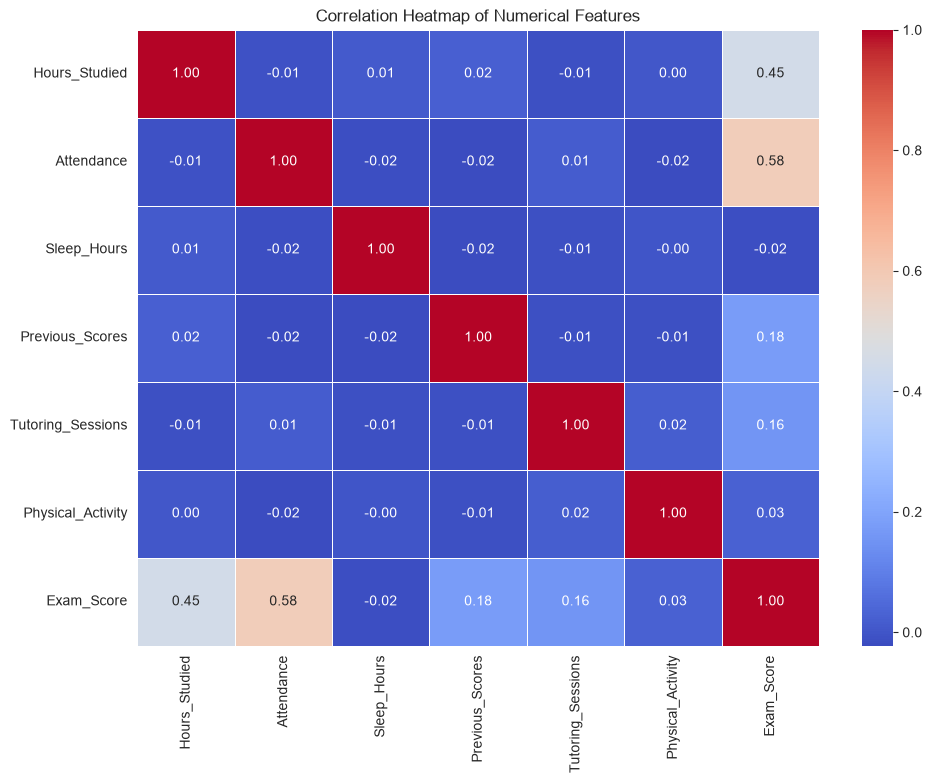

In [9]:
# Calculate correlation between numerical features

correlation_matrix = df.select_dtypes(
    include=["number"]
).corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")

plt.show()

In [10]:
# Correlation with target variable

target_correlation = correlation_matrix["Exam_Score"].drop(
    "Exam_Score"
).sort_values(ascending=False)

print("Correlation with Exam_Score:")
print(target_correlation)

Correlation with Exam_Score:
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64


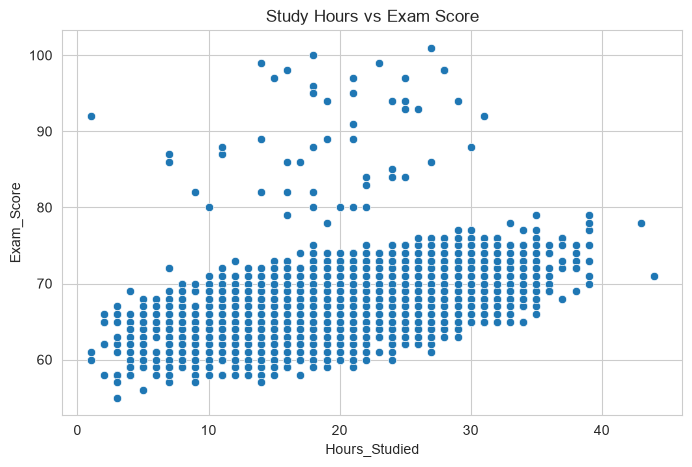

In [11]:
# Study Hours vs Exam Score

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Hours_Studied",
    y="Exam_Score"
)

plt.title("Study Hours vs Exam Score")
plt.show()

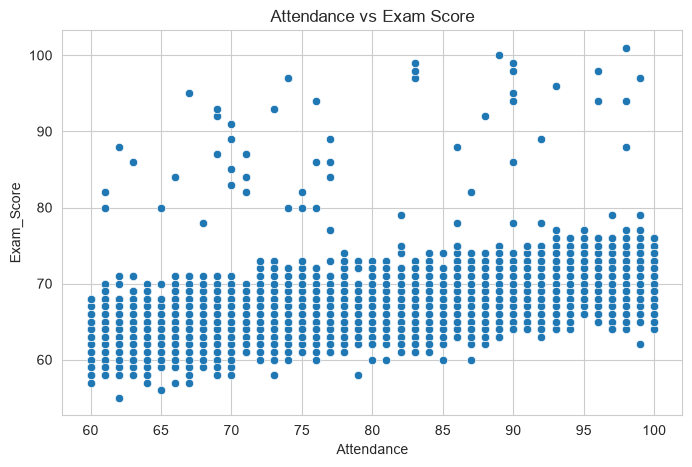

In [12]:
# Attendance vs Exam Score

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Attendance",
    y="Exam_Score"
)

plt.title("Attendance vs Exam Score")
plt.show()

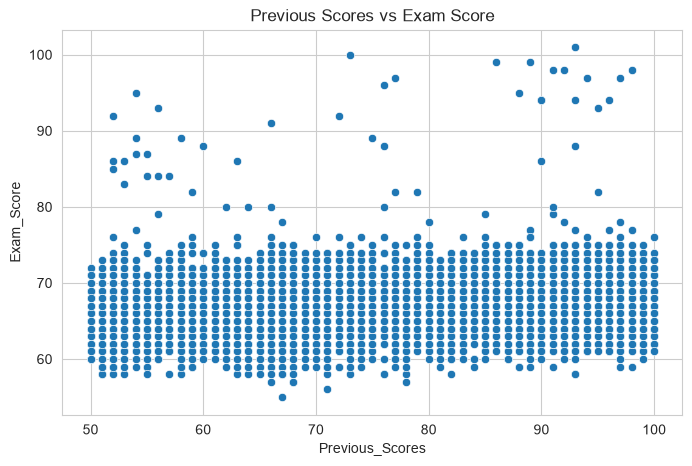

In [13]:
# Previous Scores vs Exam Score

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Previous_Scores",
    y="Exam_Score"
)

plt.title("Previous Scores vs Exam Score")
plt.show()

In [14]:
# Average exam score by categorical features

categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns.tolist()

for column in categorical_columns:

    print("\n", "=" * 50)
    print("Feature:", column)

    result = df.groupby(column, dropna=False)["Exam_Score"].agg(
        ["mean", "median", "count"]
    )

    print(result.sort_values("mean", ascending=False))


Feature: Parental_Involvement
                           mean  median  count
Parental_Involvement                          
High                  68.092767    68.0   1908
Medium                67.098156    67.0   3362
Low                   66.358265    66.0   1337

Feature: Access_to_Resources
                          mean  median  count
Access_to_Resources                          
High                 68.092152    68.0   1975
Medium               67.134378    67.0   3319
Low                  66.203351    66.0   1313

Feature: Extracurricular_Activities
                                 mean  median  count
Extracurricular_Activities                          
Yes                         67.441849    67.0   3938
No                          66.931435    67.0   2669

Feature: Motivation_Level
                       mean  median  count
Motivation_Level                          
High              67.704321    67.0   1319
Medium            67.330648    67.0   3351
Low               66.75219

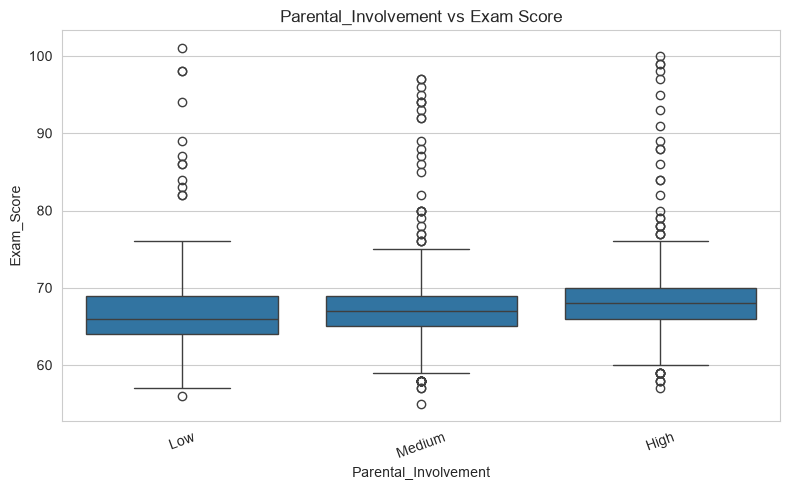

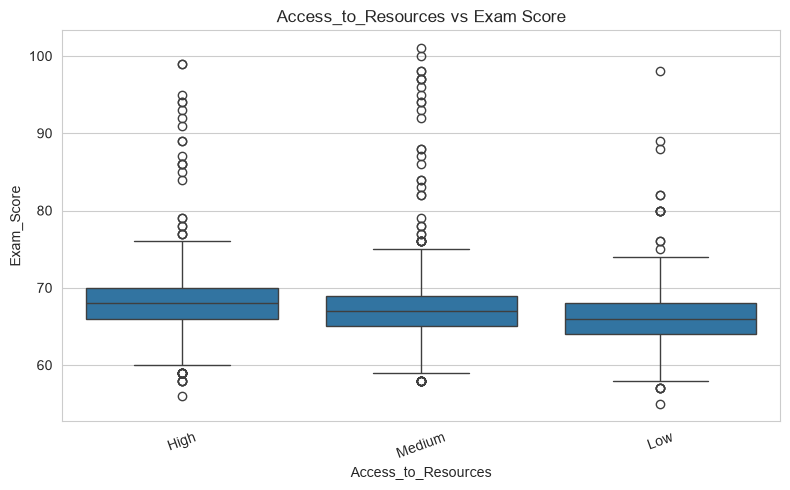

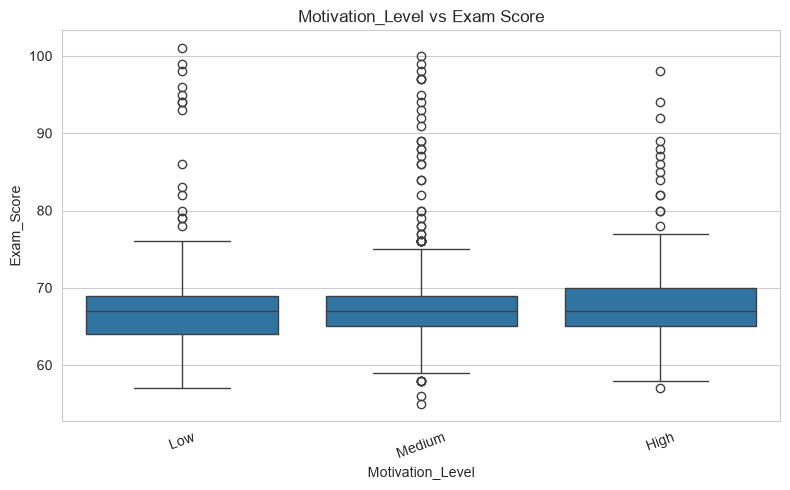

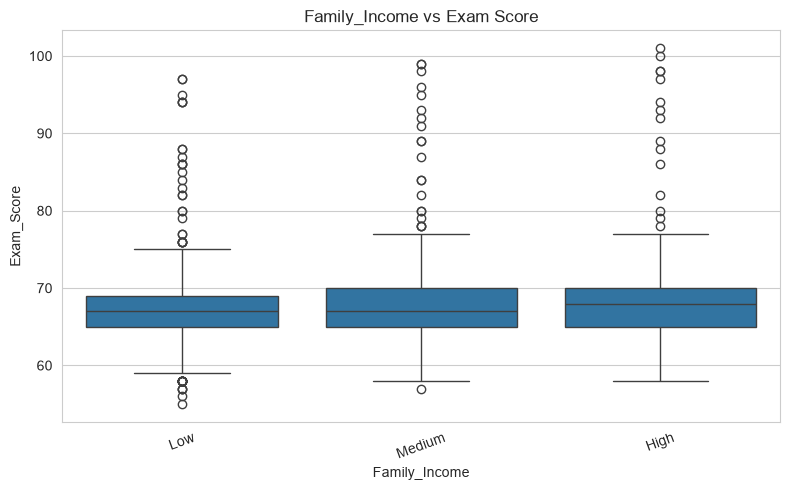

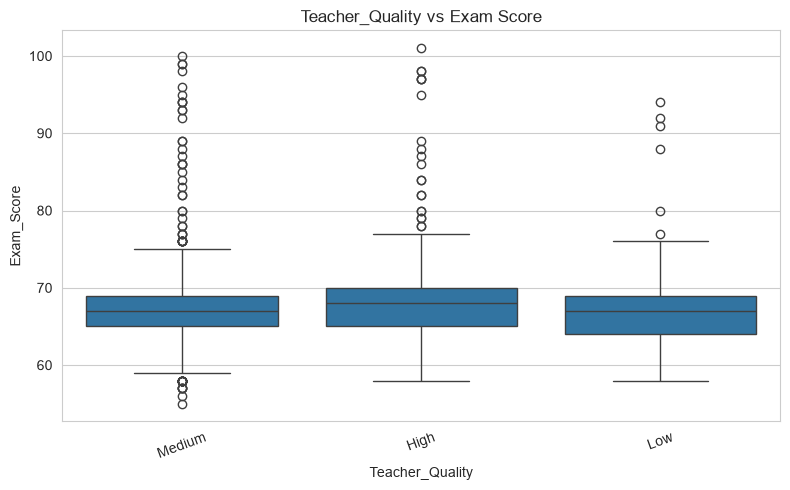

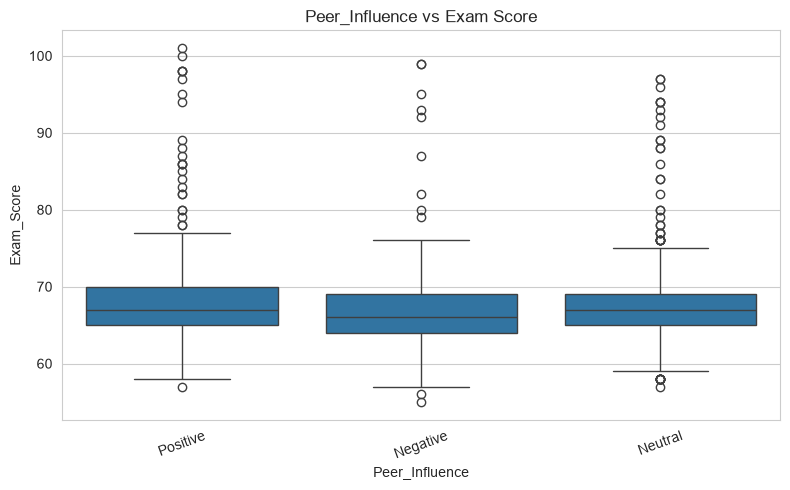

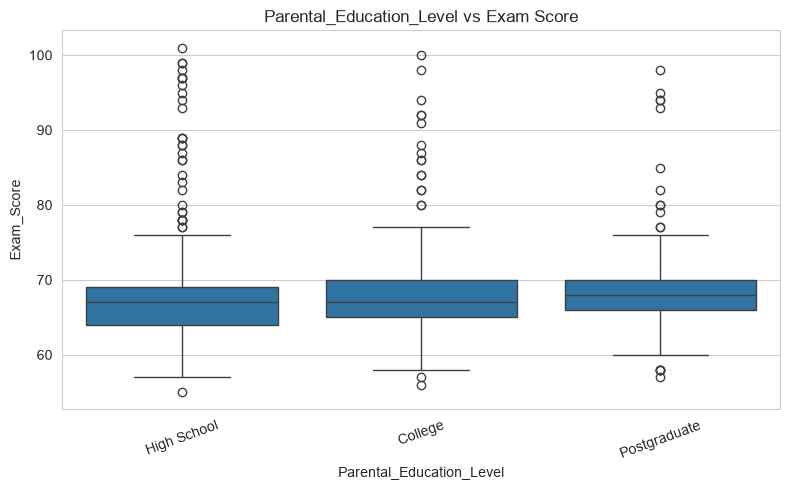

In [15]:
# Categorical feature vs Exam Score

features_to_plot = [
    "Parental_Involvement",
    "Access_to_Resources",
    "Motivation_Level",
    "Family_Income",
    "Teacher_Quality",
    "Peer_Influence",
    "Parental_Education_Level"
]

for column in features_to_plot:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=column,
        y="Exam_Score"
    )

    plt.title(f"{column} vs Exam Score")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

In [16]:
# Generate categorical feature summary

categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns.tolist()

summary_results = []

for column in categorical_columns:

    grouped = df.groupby(
        column,
        dropna=False
    )["Exam_Score"].agg(
        ["mean", "median", "count"]
    )

    for category, row in grouped.iterrows():

        summary_results.append({
            "Feature": column,
            "Category": category,
            "Average_Score": round(row["mean"], 2),
            "Median_Score": row["median"],
            "Student_Count": row["count"]
        })

categorical_summary = pd.DataFrame(summary_results)

display(categorical_summary)

,Feature,Category,Average_Score,Median_Score,Student_Count
0,Parental_Involvement,High,68.09,68.0,1908.0
1,Parental_Involvement,Low,66.36,66.0,1337.0
2,Parental_Involvement,Medium,67.10,67.0,3362.0
3,Access_to_Resources,High,68.09,68.0,1975.0
4,Access_to_Resources,Low,66.20,66.0,1313.0
5,Access_to_Resources,Medium,67.13,67.0,3319.0
6,Extracurricular_Activities,No,66.93,67.0,2669.0
7,Extracurricular_Activities,Yes,67.44,67.0,3938.0
8,Motivation_Level,High,67.70,67.0,1319.0
9,Motivation_Level,Low,66.75,67.0,1937.0


In [17]:
categorical_summary.to_csv(
    "../dataset/categorical_feature_analysis.csv",
    index=False
)

print("Categorical analysis report saved successfully!")

Categorical analysis report saved successfully!
